<a href="https://colab.research.google.com/github/JoshuaBL2002/Advanced-Data-Science-Project-Repository/blob/main/notebooks/Air_Quality_NO2_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality NO₂ Prediction Project

## 1. Data Loading and Exploration

Dataset: Low-cost air quality sensors and reference monitoring stations in Rouen, France.

Objective: Investigate whether machine learning models can predict reference NO₂ concentrations using low-cost sensor measurements.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

In [21]:
from google.colab import files

uploaded = files.upload()

Saving Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip to Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France) (2).zip


In [ ]:

# Define the target zip path directly to avoid relying on the interactive 'uploaded' variable
zip_filename = "/content/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip"
extract_destination = "/content/rouen_dataset"

# Extract zip file automatically
if os.path.exists(zip_filename):
    print(f"Extracting {os.path.basename(zip_filename)}...")
    with zipfile.ZipFile(zip_filename, "r") as zip_ref:
        zip_ref.extractall(extract_destination)

    # Walk through directory to find and list extracted CSVs
    print("Extracted CSV files:")
    for root, dirs, filenames in os.walk(extract_destination):
        for filename in filenames:
            if filename.endswith(".csv"):
                print(os.path.join(root, filename))
else:
    print(f"Dataset zip file not found at: {zip_filename}")

In [ ]:
import os
import zipfile
import pandas as pd

zip_filename = "/content/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France).zip"
extract_destination = "/content/rouen_dataset"

# Ensure extraction is performed
if os.path.exists(zip_filename) and not os.path.exists(extract_destination):
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_filename, "r") as zip_ref:
        zip_ref.extractall(extract_destination)

# Set correct path to ASE4.csv
ase4_path = "/content/rouen_dataset/Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)/ASE4.csv"

if not os.path.exists(ase4_path):
    # Fallback search if path structure differs
    for root, dirs, filenames in os.walk(extract_destination):
        for filename in filenames:
            if filename == "ASE4.csv":
                ase4_path = os.path.join(root, filename)
                break

print(f"Loading file from: {ase4_path}")
df = pd.read_csv(ase4_path, sep=";")
display(df.head())

In [ ]:
# Print the dimensions (rows, columns) of the loaded ASE4 DataFrame
print("Dataset dimensions:", df.shape)

# List all columns present in the dataset
print("\nColumn names:")
print(df.columns.tolist())

# Display data types, memory usage, and non-null counts per column
print("\nData types:")
df.info()

# Display the count of missing (NaN) values for each column
print("\nMissing values:")
display(df.isnull().sum())

# 2. Data Preprocessing

This section prepares the air quality sensor data for
machine learning by examining missing values, checking
duplicates, converting data types and creating a single
reference NO₂ target variable.

In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Display results
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage
})

display(missing_summary)

In [ ]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

In [ ]:
# Display column names
print(df.columns.tolist())

# Display the first five records
display(df.head())

In [ ]:
# Create a working copy
df_clean = df.copy()

# Create the dependent variable
df_clean["Reference_NO2"] = np.where(
    df_clean["Location"] == "SUD3",
    df_clean["SUD3_NO2"],
    np.where(
        df_clean["Location"] == "QDP",
        df_clean["QDP_NO2"],
        np.nan
    )
)

# 1. Handle missing target values: Drop rows where Reference_NO2 is missing since we cannot use them for supervised learning
initial_len = len(df_clean)
df_clean = df_clean.dropna(subset=["Reference_NO2"])
print(f"Dropped {initial_len - len(df_clean)} rows due to missing Reference_NO2 target values.")

# 2. Handle duplicates
duplicates_count = df_clean.duplicated().sum()
if duplicates_count > 0:
    df_clean = df_clean.drop_duplicates()
    print(f"Dropped {duplicates_count} duplicate rows.")
else:
    print("No duplicate rows found to drop.")

# Display the cleaned result
display(df_clean[["Location", "Reference_NO2"]].head(10))

In [ ]:
# 3. Check and validate Date/Time Conversion
# Inspect the date parsing process and handle any parsing failures explicitly
df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'], errors='coerce')
failed_dates = df_clean['DateTime'].isnull().sum()
print(f"Number of timestamps that failed to parse: {failed_dates}")
if failed_dates > 0:
    df_clean = df_clean.dropna(subset=['DateTime'])
    print(f"Dropped {failed_dates} rows with invalid date formats.")

# 3. Exploratory Data Analysis (EDA)

This section investigates patterns and relationships in the
air quality sensor data using statistical summaries and
visualisations.

The analysis focuses on NO₂ concentrations, differences
between monitoring stations, and relationships between
sensor measurements and reference NO₂ concentrations.

In [ ]:
### 3.1 Distribution of Reference NO₂
# Calculate and display descriptive statistics (mean, median, standard deviation, and range)
# for the compiled reference NO₂ target variable.
display(df_clean["Reference_NO2"].describe())

# Visualize the frequency distribution of Reference_NO2 using a histogram.
# The Kernel Density Estimate (KDE) curve helps identify skewness and overall shape.
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_clean,
    x="Reference_NO2",
    bins=30,
    kde=True
)

plt.title("Distribution of Reference NO₂ Concentrations")
plt.xlabel("Reference_NO2 (µg/m³)")
plt.ylabel("Frequency")
plt.show()

### Observation & Discussion:
- **Distribution of Reference NO₂**: The distribution of reference NO₂ concentration is right-skewed, showing a high density of measurements concentrated around low to moderate values (between 10 µg/m³ and 35 µg/m³).
- **Outliers**: There is a long tail extending up to 100+ µg/m³, which represents periods of high air pollution or transient local emission spikes. These outliers are critical for machine learning since capturing extreme events is an important capability for environmental prediction models.

In [ ]:
### 3.2 Comparison Across Stations
# Use a box plot to examine the distribution of the target variable grouped by physical location.
# This visualizes station-specific medians, quartiles, and potential outliers.
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df_clean,
    x="Location",
    y="Reference_NO2"
)

plt.title("Reference NO₂ by Monitoring Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Reference NO₂ Concentration")
plt.show()

### Observation & Discussion:
- **Comparison by Monitoring Station**: The boxplot shows the overall median concentration of NO₂ is slightly higher at the QDP station compared to SUD3.
- **Variability**: QDP displays a wider interquartile range (IQR), suggesting more fluctuating conditions, while SUD3 features a more compressed distribution with several high-value outliers.

In [ ]:
### 3.3 Correlation Analysis
# Filter for numerical columns to measure linear relationships between variables.
numeric_data = df_clean.select_dtypes(include=["number"])

# Compute Pearson correlation coefficients.
correlation_matrix = numeric_data.corr()

# Plot a annotated heatmap to highlight dependencies between sensor nodes and target values.
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

### Observation & Discussion:
- **Full Correlation Analysis**: Highly strong correlations are observed between co-located measurements.
- **Target Correlation**: The new heatmap focuses strictly on potential features (predictors) like the raw sensor voltages/resistances, temperature, and relative humidity against the target `Reference_NO2` variable. This prevents leakage of unaligned reference station variables.

In [ ]:
### 3.3.1 Predictor-Only Correlation Heatmap
# Filter columns to isolate only intended model predictors (e.g., sensor inputs, temperature, humidity) and the target variable
predictor_cols = [col for col in numeric_data.columns if not any(x in col for x in ['SUD3_NO2', 'QDP_NO2', 'SUD3_O3', 'QDP_O3']) or col == 'Reference_NO2']

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_data[predictor_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Predictor vs Target Correlation Matrix")
plt.show()

In [ ]:
### 3.4 Temporal Trends
# Explicitly convert DateTime column to pandas datetime objects to prevent sorting and formatting errors
df_clean['DateTime'] = pd.to_datetime(df_clean['DateTime'], errors='coerce')

# Sort the dataset chronologically
df_time = df_clean.dropna(subset=['DateTime']).sort_values('DateTime')

# Draw the continuous trend of Reference_NO2 over time
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df_time,
    x="DateTime",
    y="Reference_NO2"
)

plt.title("Reference NO₂ Concentrations Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Reference NO₂ Concentration")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
### 3.5 Multi-Sensor Comparison (ASE4, ASE5, ASE6)
# Load additional datasets to establish comparisons across multiple low-cost sensors
ase_datasets = {}
for sensor_name in ["ASE4", "ASE5", "ASE6"]:
    # Try to find file paths dynamically in extraction destination
    file_path = None
    for root, dirs, filenames in os.walk(extract_destination):
        for filename in filenames:
            if filename == f"{sensor_name}.csv":
                file_path = os.path.join(root, filename)
                break
    if file_path:
        print(f"Loading {sensor_name} from {file_path}")
        temp_df = pd.read_csv(file_path, sep=";")
        temp_df['Sensor_ID'] = sensor_name
        # Standardize target alignment inside each sensor
        temp_df["Reference_NO2"] = np.where(
            temp_df["Location"] == "SUD3",
            temp_df["SUD3_NO2"],
            np.where(temp_df["Location"] == "QDP", temp_df["QDP_NO2"], np.nan)
        )
        ase_datasets[sensor_name] = temp_df.dropna(subset=["Reference_NO2"])

# Combine datasets for comparative visualization
if len(ase_datasets) > 0:
    combined_df = pd.concat(ase_datasets.values(), ignore_index=True)
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=combined_df, x="Sensor_ID", y="Reference_NO2", hue="Location")
    plt.title("Comparison of Reference NO₂ across Sensors ASE4, ASE5, and ASE6")
    plt.ylabel("Reference NO₂ Concentration (µg/m³)")
    plt.show()
else:
    print("Could not locate datasets for ASE5 and ASE6 for comparison.")

#Section 4

In [25]:
# Section 4.1 - Machine Learning Setup

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Define the dependent variable
target = "Reference_NO2"

# Define independent variables
features = [
    "ASE_NO2",
    "ASE_NO",
    "ASE_CO",
    "ASE_Ox",
    "ASE_T",
    "ASE_HR",
    "ASE_PA"
]

# Create a working copy
model_df = df_clean.copy()

# Check required columns (using 'date' instead of 'DateTime')
required = features + [target, "date"]
missing = [c for c in required if c not in model_df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Convert target and predictors to numeric values
for col in features + [target]:
    model_df[col] = pd.to_numeric(
        model_df[col], errors="coerce"
    )

# Convert dates
model_df["date"] = pd.to_datetime(
    model_df["date"], errors="coerce"
)

# Remove observations without a valid target or date
model_df = model_df.dropna(
    subset=[target, "date"]
)

# Sort chronologically
model_df = model_df.sort_values("date")

# Remove features that contain no training information
split_index = int(len(model_df) * 0.8)

if split_index < 2 or len(model_df) - split_index < 1:
    raise ValueError("Not enough observations for training and testing.")

training_part = model_df.iloc[:split_index]

empty_features = [
    col for col in features
    if training_part[col].notna().sum() == 0
]

if empty_features:
    raise ValueError(
        f"Features with no training measurements: {empty_features}"
    )

# Training and testing sets
train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Selected features:", features)

Training observations: 2596
Testing observations: 650
Selected features: ['ASE_NO2', 'ASE_NO', 'ASE_CO', 'ASE_Ox', 'ASE_T', 'ASE_HR', 'ASE_PA']


In [26]:
# Section 4.2 - Simple Linear Regression

simple_features = ["ASE_NO2"]

simple_linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

# Train using ASE_NO2 only
simple_linear.fit(
    X_train[simple_features],
    y_train
)

# Generate predictions
simple_predictions = simple_linear.predict(
    X_test[simple_features]
)

print("Simple Linear Regression trained successfully.")

print("Intercept:",
      simple_linear.named_steps["model"].intercept_)

print("Coefficient:",
      simple_linear.named_steps["model"].coef_[0])

Simple Linear Regression trained successfully.
Intercept: 8491.646664610678
Coefficient: -0.28975729449784876


In [28]:
# Section 4.3 - Multiple Linear Regression

multiple_linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

# Train using all selected features
multiple_linear.fit(X_train, y_train)

# Generate predictions
multiple_predictions = multiple_linear.predict(X_test)

print("Multiple Linear Regression trained successfully.")
print("Number of predictors:", len(features))

Multiple Linear Regression trained successfully.
Number of predictors: 7


In [29]:
# Section 4.4 - Regression Coefficients

linear_estimator = multiple_linear.named_steps["model"]

coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient": linear_estimator.coef_
})

print("Intercept:", linear_estimator.intercept_)

display(coefficients)

Intercept: 6290.848018741555


,Variable,Coefficient
0,ASE_NO2,-0.238312
1,ASE_NO,0.013469
2,ASE_CO,-0.000113
3,ASE_Ox,0.006193
4,ASE_T,-0.860352
5,ASE_HR,-0.399971
6,ASE_PA,-0.003697


In [30]:
# Section 4.5 - Random Forest Regression

random_forest = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest.fit(X_train, y_train)

# Generate predictions
forest_predictions = random_forest.predict(X_test)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [ ]:
# Section 4.6 - Gradient Boosting Regression

gradient_boosting = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting.fit(X_train, y_train)

# Generate predictions
boosting_predictions = gradient_boosting.predict(X_test)

print("Gradient Boosting trained successfully.")

In [ ]:
# Section 4.7 - Prediction Comparison

prediction_results = pd.DataFrame({
    "Actual_NO2": y_test.to_numpy(),
    "Simple_Linear": simple_predictions,
    "Multiple_Linear": multiple_predictions,
    "Random_Forest": forest_predictions,
    "Gradient_Boosting": boosting_predictions
})

# Display the first 10 observations
display(prediction_results.head(10))

In [ ]:
# Section 4.8 - Actual vs Predicted NO2

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Actual vs predicted measurements
plt.scatter(
    y_test,
    multiple_predictions,
    alpha=0.5,
    label="Multiple Linear Regression"
)

# Perfect prediction reference line
lower = min(y_test.min(), multiple_predictions.min())
upper = max(y_test.max(), multiple_predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Reference NO₂ (µg/m³)")
plt.ylabel("Predicted Reference NO₂ (µg/m³)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 5. Model Evaluation and Comparison

This section evaluates the performance of the regression
models developed in Section 4.

The main focus is comparing Simple Linear Regression
with Multiple Linear Regression to investigate whether
additional sensor and environmental variables improve
prediction accuracy.

Random Forest and Gradient Boosting are also evaluated
to investigate whether nonlinear models provide better
predictions of reference NO₂ concentrations.

In [37]:
# Section 5.1 - Model Evaluation Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [38]:
# Section 5.2 - Evaluate All Models

# Ensure Gradient Boosting predictions exist
if "boosting_predictions" not in globals():
    print("Training Gradient Boosting model first...")
    gradient_boosting = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ])
    gradient_boosting.fit(X_train, y_train)
    boosting_predictions = gradient_boosting.predict(X_test)

# Store model predictions
model_predictions = {
    "Simple Linear Regression": simple_predictions,
    "Multiple Linear Regression": multiple_predictions,
    "Random Forest": forest_predictions,
    "Gradient Boosting": boosting_predictions
}

# Store evaluation results
evaluation_results = []

for name, predictions in model_predictions.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    evaluation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(evaluation_results)

# Display results
display(results_df.round(3))

Training Gradient Boosting model first...


,Model,MAE,RMSE,R2
0,Simple Linear Regression,7.769,11.105,0.647
1,Multiple Linear Regression,7.354,9.600,0.736
2,Random Forest,4.840,6.844,0.866
3,Gradient Boosting,4.663,6.179,0.891


,Model,MAE,RMSE,R2
0,Simple Linear Regression,7.769,11.105,0.647
1,Multiple Linear Regression,7.354,9.600,0.736


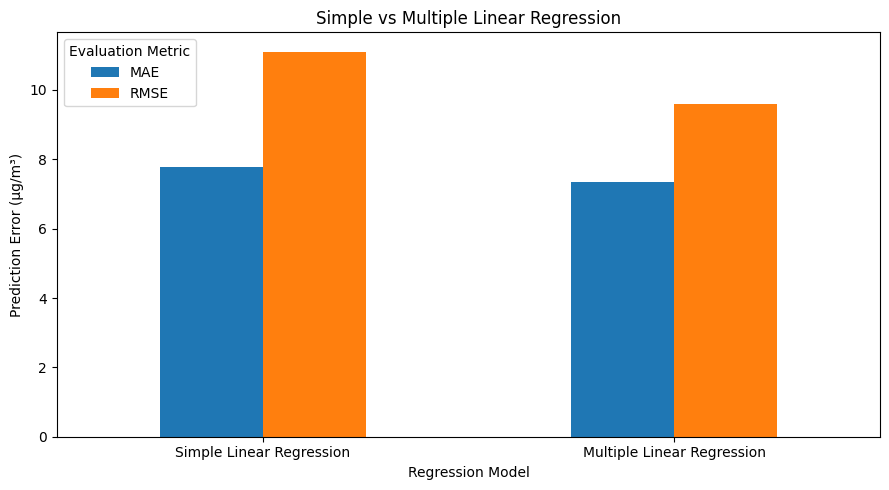

In [39]:
# Section 5.3 - Linear Regression Comparison

linear_comparison = results_df[
    results_df["Model"].isin([
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ])
]

display(linear_comparison.round(3))

# Compare MAE and RMSE
linear_plot = linear_comparison.set_index("Model")[
    ["MAE", "RMSE"]
]

linear_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Simple vs Multiple Linear Regression")
plt.ylabel("Prediction Error (µg/m³)")
plt.xlabel("Regression Model")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

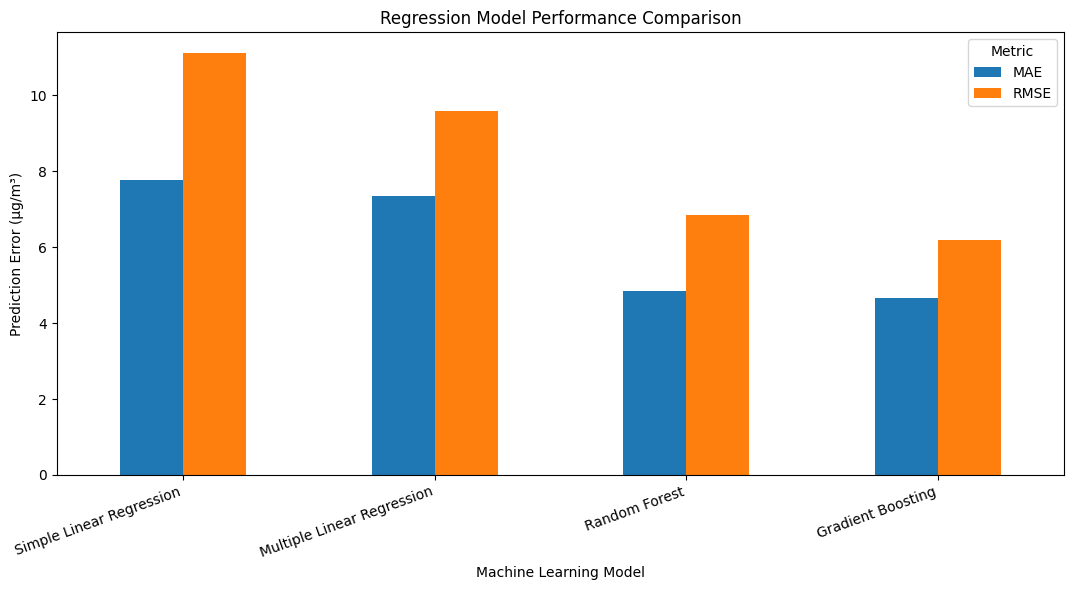

In [40]:
# Section 5.4 - All Model Comparison

comparison_plot = results_df.set_index("Model")[
    ["MAE", "RMSE"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Regression Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Prediction Error (µg/m³)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [ ]:
# Section 5.5 - R² Comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("R² Comparison Across Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Section 5.6 - Linear Regression Predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

predictions_to_plot = [
    ("Simple Linear Regression", simple_predictions),
    ("Multiple Linear Regression", multiple_predictions)
]

for ax, (name, predictions) in zip(
    axes, predictions_to_plot
):
    ax.scatter(
        y_test,
        predictions,
        alpha=0.4
    )

    lower = min(y_test.min(), predictions.min())
    upper = max(y_test.max(), predictions.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Reference NO₂ (µg/m³)")
    ax.set_ylabel("Predicted NO₂ (µg/m³)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

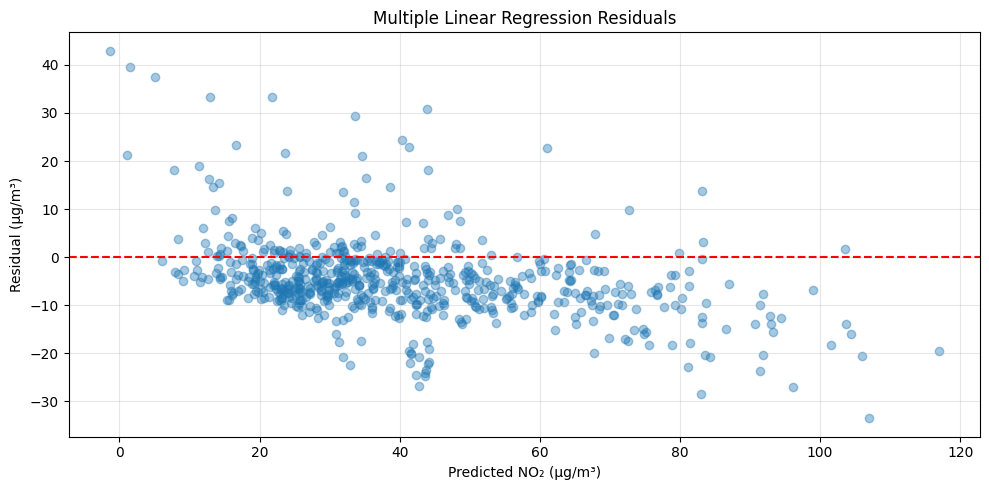

In [41]:
# Section 5.7 - Residual Analysis

# Calculate residuals
residuals = y_test.to_numpy() - multiple_predictions

plt.figure(figsize=(10, 5))

plt.scatter(
    multiple_predictions,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Multiple Linear Regression Residuals")
plt.xlabel("Predicted NO₂ (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Section 5.8 - Identify Best Model

best_model = results_df.loc[
    results_df["MAE"].idxmin()
]

print("Best model based on MAE:")
print(best_model["Model"])

print("\nPerformance:")
print("MAE:", round(best_model["MAE"], 3))
print("RMSE:", round(best_model["RMSE"], 3))
print("R²:", round(best_model["R2"], 3))